# Importing

In [8]:

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy import stats

ROOT = Path.cwd()

M1_PATH = (
    ROOT / "data"
    / "XAUUSD_M1_202602020001_202608312258.csv"
)

LABELS_PATH = (
    ROOT / "data"
    / "MILKY_Recovery_Labels_202603_202608.csv"
)

FIGS = ROOT / "reports" / "figures"
OUT_PARQUET = ROOT / "data" / "interim" / "m1_clean.parquet"


if not M1_PATH.is_file():
    raise FileNotFoundError(
        f"Khong tim thay file M1:\n{M1_PATH}\n"
        "Hay kiem tra lai ROOT va duong dan file."
    )

if not LABELS_PATH.is_file():
    raise FileNotFoundError(
        f"Khong tim thay file labels:\n{LABELS_PATH}\n"
        "Hay kiem tra lai ROOT va duong dan file."
    )

FIGS.mkdir(parents=True, exist_ok=True)
OUT_PARQUET.parent.mkdir(parents=True, exist_ok=True)

print("Da tim thay cac file du lieu.")
print(f"M1 CSV: {M1_PATH}")
print(f"Labels CSV: {LABELS_PATH}")
print(f"Thu muc luu bieu do: {FIGS}")
print(f"Thu muc luu Parquet: {OUT_PARQUET.parent}")


plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["figure.dpi"] = 110


def show_plot(fig, filename):
    """
    Lưu biểu đồ vào reports/figures,
    hiển thị trong Notebook rồi đóng figure.
    """
    output_path = FIGS / filename

    fig.tight_layout()
    fig.savefig(
        output_path,
        dpi=150,
        bbox_inches="tight",
    )

    display(fig)
    plt.close(fig)

    print(f"Da luu bieu do: {output_path}")


Da tim thay cac file du lieu.
M1 CSV: d:\Academic\UET\ATCS\shock-detector\data\XAUUSD_M1_202602020001_202608312258.csv
Labels CSV: d:\Academic\UET\ATCS\shock-detector\data\MILKY_Recovery_Labels_202603_202608.csv
Thu muc luu bieu do: d:\Academic\UET\ATCS\shock-detector\reports\figures
Thu muc luu Parquet: d:\Academic\UET\ATCS\shock-detector\data\interim


# Định nghĩa các hàm
- read_mt5_m1: đọc dữ liệu
- clean_m1: làm sạch
- load_labels: tải nhãn
- hour_coverage: tính độ bao phủ nến theo giờ và tháng
- spread_summary: tính các phân vị từ 1-99% cùng spread trung vị theo giờ
- attach_last_closed: sau khi áp dụng offset, tìm nến M1 gần nhất để ghép nhãn recovery
- signed_pre_returns: tính lợi suất giá nhìn ngược từ 1', 2', 3' trước thời điểm sự kiện
- daily_rv(m1): tính realized volatility hàng ngày

In [ ]:
ONE_MIN = pd.Timedelta(minutes=1)
MIN_BARS_FULL_DAY = 600
HORIZONS = (1, 2, 3, 4, 5)
OFFSETS_H = tuple(range(-3, 4))
SCORE_H = 5
MT5_COLUMNS = {
    "<DATE>": "date", "<TIME>": "clock", "<OPEN>": "open", "<HIGH>": "high",
    "<LOW>": "low", "<CLOSE>": "close", "<TICKVOL>": "tick_volume",
    "<VOL>": "real_volume", "<SPREAD>": "spread",
}


def read_mt5_m1(path):
    with open(path, "r", encoding="utf-8-sig", errors="replace") as file:
        first_line = file.readline()
    separator = next((item for item in ("\t", ";", ",") if item in first_line), None)
    if separator is None:
        raise ValueError(f"Loi: {first_line!r}")
    df = pd.read_csv(path, sep=separator, encoding="utf-8-sig")
    df.columns = [column.strip() for column in df.columns]
    missing = [column for column in MT5_COLUMNS if column not in df.columns and column != "<VOL>"]
    if missing:
        raise ValueError(f"Thieu cat MT5: {missing}; c?: {list(df.columns)}")
    df = df.rename(columns=MT5_COLUMNS)
    df["time"] = pd.to_datetime(
        df["date"].astype(str) + " " + df["clock"].astype(str),
        format="%Y.%m.%d %H:%M:%S",
    )
    return df[["time", "open", "high", "low", "close", "tick_volume", "spread"]]


def clean_m1(raw):
    df = raw.copy()
    prices = df[["open", "high", "low", "close"]]
    invalid = prices.isna().any(axis=1) | (prices <= 0).any(axis=1)
    df = df.loc[~invalid].drop_duplicates()
    df = df.sort_values("time", kind="stable").drop_duplicates("time", keep="last").reset_index(drop=True)
    df["gap_min"] = df["time"].diff().dt.total_seconds().div(60)
    return df


def hour_coverage(df):
    weekdays = df[df["time"].dt.weekday < 5]
    days = weekdays.groupby(weekdays["time"].dt.to_period("M").astype(str))["time"].apply(
        lambda values: values.dt.normalize().nunique()
    )
    counts = weekdays.groupby(
        [weekdays["time"].dt.to_period("M").astype(str), weekdays["time"].dt.hour]
    ).size().unstack(fill_value=0).reindex(columns=range(24), fill_value=0)
    return counts.div(days * 60, axis=0)


def spread_summary(df):
    spread = df["spread"]
    quantiles = spread.quantile([0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99])
    quantiles.index = [f"q{int(value * 100):02d}" for value in quantiles.index]
    return quantiles, df.groupby(df["time"].dt.hour)["spread"].median()


def load_labels(path):
    df = pd.read_csv(path, sep=";")
    df.columns = [column.strip() for column in df.columns]
    timestamp = df["timestamp"].astype(str).str.strip()
    try:
        df["timestamp"] = pd.to_datetime(timestamp, format="ISO8601").astype("datetime64[ns]")
    except (ValueError, TypeError):
        normalized = timestamp.str.replace(".", "-", n=2, regex=False)
        df["timestamp"] = pd.to_datetime(normalized, format="mixed").astype("datetime64[ns]")
    df["side"] = df["side"].astype(str).str.upper().str.strip()
    df["sign"] = np.where(df["side"] == "BUY", 1, -1)
    return df.sort_values(["timestamp", "basket_id", "Ri"]).reset_index(drop=True)


def attach_last_closed(events, m1, cols=(), offset=pd.Timedelta(0), time_col="timestamp"):
    bars = m1[["time", *cols]].copy()
    bars["time"] = bars["time"].astype("datetime64[ns]")
    bars["_pos"] = np.arange(len(bars))
    if not bars["time"].is_monotonic_increasing:
        raise ValueError("M1 phai duoc sap xep tang dan theo tgian.")
    event_rows = events.copy()
    event_rows["_key"] = (pd.to_datetime(event_rows[time_col]) + offset).dt.floor("min") - ONE_MIN
    event_rows["_order"] = np.arange(len(event_rows))
    matched = pd.merge_asof(
        event_rows.sort_values("_key")[["_key", "_order"]],
        bars.rename(columns={"time": "_bar"}),
        left_on="_key", right_on="_bar", direction="backward", allow_exact_matches=True,
    ).sort_values("_order").set_index(event_rows.index)
    event_rows["m1_bar_time"] = matched["_bar"]
    event_rows["m1_pos"] = matched["_pos"].astype("Int64")
    event_rows["m1_bar_age_min"] = (matched["_key"] - matched["_bar"]).dt.total_seconds().div(60)
    for column in cols:
        event_rows[f"m1_{column}"] = matched[column]
    return event_rows.drop(columns=["_key", "_order"])


def signed_pre_returns(events, m1, offset=pd.Timedelta(0), horizons=HORIZONS):
    matched = attach_last_closed(events, m1, offset=offset)
    log_close = np.log(m1["close"].to_numpy())
    bar_times = m1["time"].to_numpy()
    positions = matched["m1_pos"].to_numpy(dtype="float")
    valid_bar = (matched["m1_bar_age_min"].to_numpy() == 0) & ~np.isnan(positions)
    result = pd.DataFrame(index=matched.index)
    result["no_bar"] = ~valid_bar
    current = np.where(valid_bar, positions, 0).astype(int)
    for horizon in horizons:
        previous = current - horizon
        valid = valid_bar & (previous >= 0)
        previous = np.where(valid, previous, 0)
        contiguous = (bar_times[current] - bar_times[previous]) == np.timedelta64(horizon, "m")
        returns = np.where(
            valid & contiguous,
            (log_close[current] - log_close[previous]) * matched["sign"].to_numpy(),
            np.nan,
        )
        result[f"r{horizon}"] = returns * 1e4
    return result


def summarize_returns(returns):
    summary = {"n": int(returns[f"r{SCORE_H}"].notna().sum()), "frac_no_bar": returns["no_bar"].mean()}
    for horizon in HORIZONS:
        values = returns[f"r{horizon}"].dropna()
        summary[f"mean_r{horizon}_bp"] = values.mean()
        summary[f"t_r{horizon}"] = (
            values.mean() / (values.std(ddof=1) / np.sqrt(len(values))) if len(values) > 2 else np.nan
        )
        summary[f"neg_r{horizon}"] = (values < 0).mean()
    return summary


def alignment_scan(events, m1, offsets_min):
    rows = []
    for offset_min in offsets_min:
        returns = signed_pre_returns(events, m1, pd.Timedelta(minutes=int(offset_min)))
        rows.append({"offset_min": int(offset_min), **summarize_returns(returns)})
    return pd.DataFrame(rows)


def alignment_scan_monthly(events, m1, offsets_min):
    months = events["timestamp"].dt.to_period("M").astype(str)
    rows = []
    for offset_min in offsets_min:
        returns = signed_pre_returns(events, m1, pd.Timedelta(minutes=int(offset_min)))
        for month, indices in returns.groupby(months).groups.items():
            rows.append({"month": month, "offset_min": int(offset_min), **summarize_returns(returns.loc[indices])})
    return pd.DataFrame(rows)


def mean_pre_path(events, m1, offset=pd.Timedelta(0), max_lag=30):
    returns = signed_pre_returns(events, m1, offset, horizons=range(1, max_lag + 1))
    return pd.Series({lag: returns[f"r{lag}"].mean() for lag in range(1, max_lag + 1)})


def daily_rv(m1):
    returns = np.log(m1["close"]).diff()
    returns[m1["gap_min"] != 1] = np.nan
    day = m1["time"].dt.normalize()
    grouped = pd.DataFrame({"r2": returns ** 2}).groupby(day)
    daily = pd.DataFrame({
        "n_bars": m1.groupby(day).size(),
        "rv_pct": 100 * np.sqrt(grouped["r2"].sum()),
        "range_usd": m1.groupby(day)["high"].max() - m1.groupby(day)["low"].min(),
    })
    return daily[daily["n_bars"] >= MIN_BARS_FULL_DAY]


def rv_vs_baskets(m1, labels):
    daily = daily_rv(m1)
    first_recovery = labels[labels["Ri"] == 1]
    basket_counts = first_recovery.groupby(first_recovery["timestamp"].dt.normalize()).size().rename("baskets")
    joined = daily.join(basket_counts, how="left")
    in_label_period = (joined.index >= labels["timestamp"].min().normalize()) & (
        joined.index <= labels["timestamp"].max().normalize()
    )
    joined = joined[in_label_period].copy()
    joined["active"] = joined["baskets"].fillna(0) > 0
    joined["month"] = joined.index.to_period("M").astype(str)
    monthly = joined.groupby("month").agg(
        days=("rv_pct", "size"), rv_day_pct=("rv_pct", "mean"),
        range_usd=("range_usd", "mean"), active_days=("active", "sum"),
    )
    monthly["baskets_per_active_day"] = joined[joined["active"]].groupby("month")["baskets"].mean()
    active = joined[joined["active"]]
    results = {
        "spearman_month": stats.spearmanr(monthly["rv_day_pct"], monthly["baskets_per_active_day"]),
        "spearman_day": stats.spearmanr(active["rv_pct"], active["baskets"]),
        "n_days": len(active),
    }
    return monthly, results, active


def price_range_by_step(labels, m1, offset=pd.Timedelta(0)):
    events = attach_last_closed(labels, m1, cols=("close",), offset=offset).rename(columns={"m1_close": "price"})
    first_price = events[events["Ri"] == 1].set_index("basket_id")["price"]
    events["p1"] = events["basket_id"].map(first_price)
    events["move_signed"] = (events["price"] - events["p1"]) * events["sign"]
    events["dist"] = (events["price"] - events["p1"]).abs()
    events["M"] = events.groupby("basket_id")["Ri"].transform("max")
    result = events[(events["Ri"] >= 2) & events["price"].notna() & events["p1"].notna()].copy()
    result["step_usd"] = result["dist"] / (result["Ri"] - 1)
    return result


def range_correlations(price_range):
    last = price_range[price_range["Ri"] == price_range["M"]]
    rows = []
    for sample, frame in (("rows_k>=2", price_range), ("one_per_basket_at_M", last)):
        pearson = stats.pearsonr(frame["Ri"], frame["dist"])
        spearman = stats.spearmanr(frame["Ri"], frame["dist"])
        rows.append({
            "sample": sample, "n": len(frame), "pearson": pearson.statistic,
            "spearman": spearman.statistic, "frac_adverse": (frame["move_signed"] < 0).mean(),
        })
    return pd.DataFrame(rows)


# Đọc và làm sạch M1
Đọc cột ngày giờ theo định dang MT5, bỏ dòng giá thiếu, loại duplicate

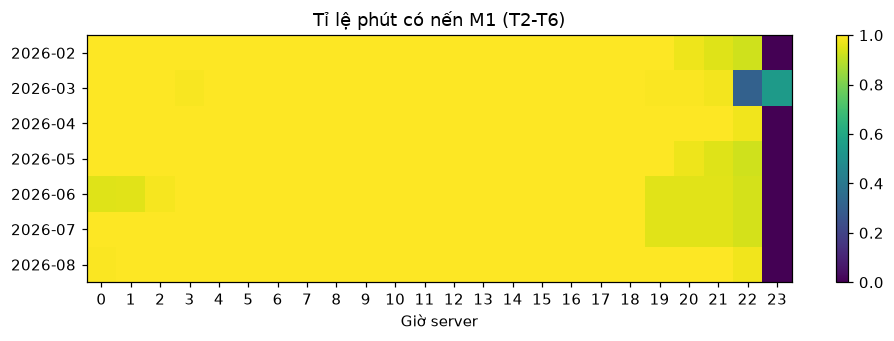

Da luu bieu do: d:\Academic\UET\ATCS\shock-detector\reports\figures\g3_hour_coverage.png


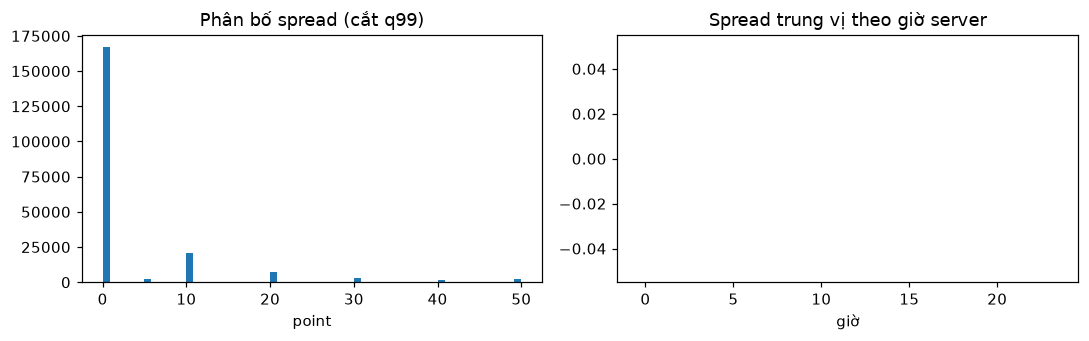

Da luu bieu do: d:\Academic\UET\ATCS\shock-detector\reports\figures\g3_spread.png


In [11]:
raw = read_mt5_m1(M1_PATH)
m1 = clean_m1(raw)
m1.to_parquet(OUT_PARQUET, index=False)

coverage = hour_coverage(m1)
fig, ax = plt.subplots(figsize=(9, 3.2))
image = ax.imshow(coverage.values, aspect="auto", cmap="viridis", vmin=0, vmax=1)
ax.set_yticks(range(len(coverage)))
ax.set_yticklabels(coverage.index)
ax.set_xticks(range(24))
ax.set_xlabel("Giờ server")
ax.set_title("Tỉ lệ phút có nến M1 (T2-T6)")
fig.colorbar(image, ax=ax)
show_plot(fig, "g3_hour_coverage.png")

spread_quantiles, spread_by_hour = spread_summary(m1)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].hist(m1["spread"].clip(upper=spread_quantiles["q99"]), bins=60)
ax[0].set_title("Phân bố spread (cắt q99)")
ax[0].set_xlabel("point")
ax[1].bar(spread_by_hour.index, spread_by_hour.values)
ax[1].set_title("Spread trung vị theo giờ server")
ax[1].set_xlabel("giờ")
show_plot(fig, "g3_spread.png")

# Phân tích mqh biến động giữa giá xauusd trước recovery và hướng basket (buy hoặc sell), tìm offset cho kết quả rõ nhất

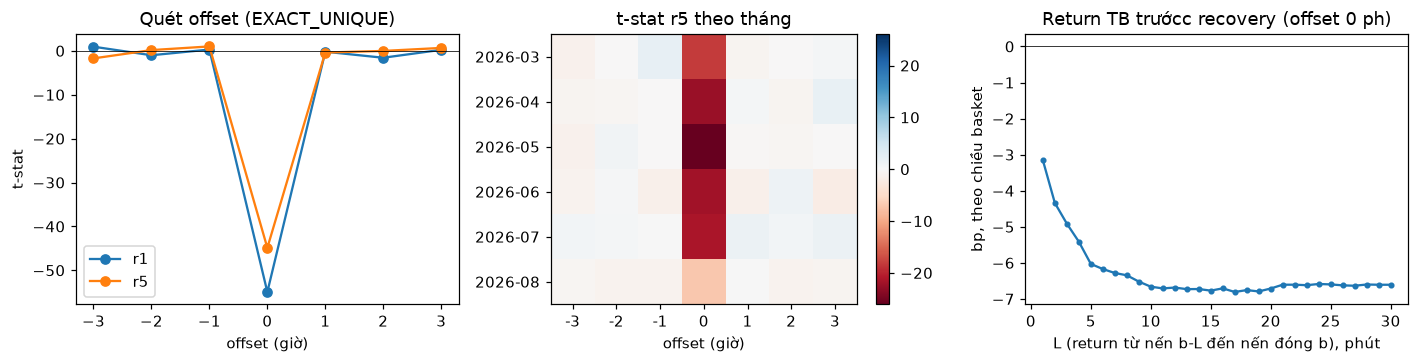

Da luu bieu do: d:\Academic\UET\ATCS\shock-detector\reports\figures\g3_alignment.png


In [12]:
labels = load_labels(LABELS_PATH)
exact_labels = labels[labels["timestamp_quality"] == "EXACT_UNIQUE"].reset_index(drop=True)
hour_offsets = [60 * hour for hour in OFFSETS_H]
alignment = alignment_scan(exact_labels, m1, hour_offsets)
best_offset = int(alignment.loc[alignment[f"t_r{SCORE_H}"].idxmin(), "offset_min"])
monthly_alignment = alignment_scan_monthly(exact_labels, m1, hour_offsets)
monthly_t = monthly_alignment.pivot(index="month", columns="offset_min", values=f"t_r{SCORE_H}")
offset = pd.Timedelta(minutes=best_offset)
pre_recovery_path = mean_pre_path(exact_labels, m1, offset)

fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
for horizon in (1, 5):
    ax[0].plot(alignment["offset_min"] / 60, alignment[f"t_r{horizon}"], "o-", label=f"r{horizon}")
ax[0].axhline(0, color="k", linewidth=0.5)
ax[0].set_xlabel("offset (giờ)")
ax[0].set_ylabel("t-stat")
ax[0].legend()
ax[0].set_title("Quét offset (EXACT_UNIQUE)")

max_t = np.nanmax(np.abs(monthly_t.values))
image = ax[1].imshow(monthly_t.values, aspect="auto", cmap="RdBu", vmin=-max_t, vmax=max_t)
ax[1].set_xticks(range(monthly_t.shape[1]))
ax[1].set_xticklabels((monthly_t.columns / 60).astype(int))
ax[1].set_yticks(range(len(monthly_t)))
ax[1].set_yticklabels(monthly_t.index)
ax[1].set_xlabel("offset (giờ)")
ax[1].set_title(f"t-stat r{SCORE_H} theo tháng")
fig.colorbar(image, ax=ax[1])

ax[2].plot(pre_recovery_path.index, pre_recovery_path.values, "o-", markersize=3)
ax[2].axhline(0, color="k", linewidth=0.5)
ax[2].set_xlabel("L (return từ nến b-L đến nến đóng b), phút")
ax[2].set_ylabel("bp, theo chiều basket")
ax[2].set_title(f"Return TB trướcc recovery (offset {best_offset} ph)")
show_plot(fig, "g3_alignment.png")

# Phân tích giữa độ biến động và số lượng recovery basket kích hoạt, theo tháng và ngày

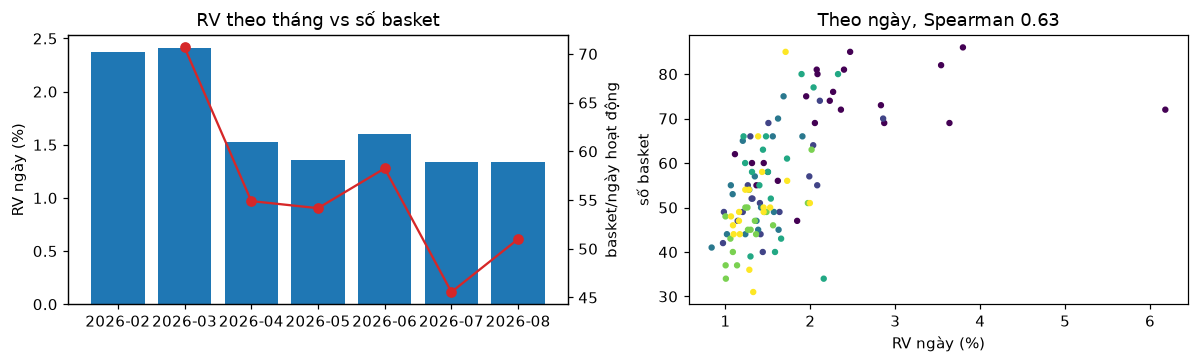

Da luu bieu do: d:\Academic\UET\ATCS\shock-detector\reports\figures\g3_rv_vs_baskets.png


In [ ]:
monthly_rv, rv_results, daily_rv_baskets = rv_vs_baskets(m1, labels)
daily_rv_data = daily_rv(m1)
monthly_rv_all = daily_rv_data.groupby(daily_rv_data.index.to_period("M").astype(str))["rv_pct"].mean()
daily_spearman = rv_results["spearman_day"]

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].bar(monthly_rv_all.index, monthly_rv_all.values, color="C0", label="RV ngày TB (%)")
ax[0].set_ylabel("RV ngày (%)")
basket_axis = ax[0].twinx()
basket_axis.plot(
    monthly_rv.index,
    monthly_rv["baskets_per_active_day"],
    "o-",
    color="C3",
    label="basket/ngày",
)
basket_axis.set_ylabel("basket/ngày hoạt động")
ax[0].set_title("RV theo tháng vs số basket")
ax[1].scatter(
    daily_rv_baskets["rv_pct"],
    daily_rv_baskets["baskets"],
    s=10,
    c=pd.factorize(daily_rv_baskets["month"])[0],
    cmap="viridis",
)
ax[1].set_xlabel("RV ngày (%)")
ax[1].set_ylabel("số basket")
ax[1].set_title(f"Theo ngày, Spearman {daily_spearman.statistic:.2f}")
show_plot(fig, "g3_rv_vs_baskets.png")

# Phân tích k và quãng giá, ước lượng bước giá ngầm định

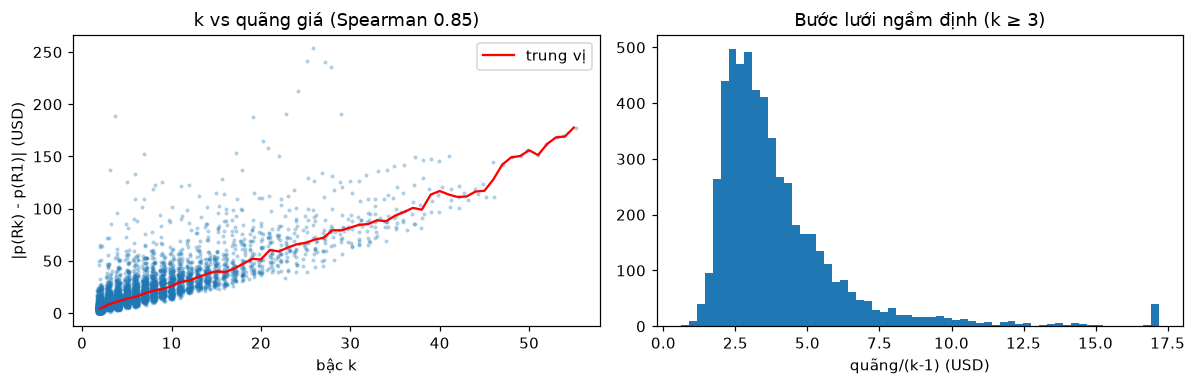

Da luu bieu do: d:\Academic\UET\ATCS\shock-detector\reports\figures\g3_k_vs_range.png


In [14]:
price_range = price_range_by_step(labels, m1, offset)
price_range.to_parquet(ROOT / "data" / "interim" / "g3_price_range.parquet", index=False)
range_correlations_table = range_correlations(price_range)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
rng = np.random.default_rng(0)
ax[0].scatter(
    price_range["Ri"] + rng.uniform(-0.3, 0.3, len(price_range)),
    price_range["dist"],
    s=3,
    alpha=0.25,
)
median_distance = price_range.groupby("Ri")["dist"].median()
ax[0].plot(median_distance.index, median_distance.values, "r-", linewidth=1.5, label="trung vị")
ax[0].set_xlabel("bậc k")
ax[0].set_ylabel("|p(Rk) - p(R1)| (USD)")
ax[0].legend()
ax[0].set_title(f"k vs quãng giá (Spearman {range_correlations_table.spearman.iloc[0]:.2f})")
ax[1].hist(
    price_range.loc[price_range.Ri >= 3, "step_usd"].clip(
        upper=price_range.step_usd.quantile(0.99)
    ),
    bins=60,
)
ax[1].set_xlabel("quãng/(k-1) (USD)")
ax[1].set_title("Bước lưới ngầm định (k ≥ 3)")
show_plot(fig, "g3_k_vs_range.png")